# C3 tutorial

[Open in Colab](https://colab.research.google.com/github/mapequation/c3/blob/main/python/examples/tutorial.ipynb)

C3 (Consistent Categorical Colors) gives you distinct colors for categories: the same colors every time, and asking for more never changes the ones you already have.
It also colors nested categories, such as the modules of a network found by [Infomap](https://www.mapequation.org/infomap), so that submodules get shades of their parent's color.
This notebook walks through the basics and then colors two maps: US states by Census region and division, and the modules of a network.

Install it with

```sh
pip install c3-colors
```

and import it as `c3`. It has no dependencies. This notebook also uses matplotlib, networkx, geopandas and infomap, which the next cell installs if you run it on Colab.

In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install --quiet c3-colors matplotlib networkx geopandas infomap

The figures use a transparent background and gray text, so they read on light and dark pages.

In [2]:
import c3
import matplotlib.pyplot as plt

%config InlineBackend.figure_formats = ["svg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "metadata": {"Date": None}}

gray = "#888"
plt.rcParams.update({
    "figure.facecolor": "none",
    "axes.facecolor": "none",
    "axes.edgecolor": gray,
    "axes.labelcolor": gray,
    "text.color": gray,
    "xtick.color": gray,
    "ytick.color": gray,
    "legend.frameon": False,
    "svg.fonttype": "none",  # keep text as text
    "svg.hashsalt": "c3",  # fixed ids, so re-runs give small diffs
})

## Palettes

`c3.palette(n)` returns `n` colors as hex strings.

In [3]:
colors = c3.palette(8)
colors

['#279ff2',
 '#dc9b5a',
 '#2e915b',
 '#c06caf',
 '#00b6be',
 '#d15259',
 '#999a3e',
 '#a698f1']

A small helper draws lists of colors as rows of swatches.

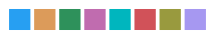

In [4]:
def show(*rows, labels=None):
    """Draw each list of colors as a row of swatches."""
    n = max(len(row) for row in rows)
    size = min(0.45, 9 / n)  # inches per swatch
    fig, ax = plt.subplots(figsize=(size * n, size * len(rows)))
    for y, row in enumerate(rows):
        ax.bar(range(len(row)), 0.85, bottom=y - 0.425, width=0.85, color=row)
    ax.set(xlim=(-0.5, n - 0.5), ylim=(len(rows) - 0.5, -0.5), xticks=[])
    ax.set_yticks(range(len(rows)), labels or [""] * len(rows))
    ax.tick_params(left=False)
    ax.spines[:].set_visible(False)
    plt.show()


show(colors)

Every palette is drawn from one fixed, endless sequence of colors, so a longer palette starts with the shorter one.

In [5]:
c3.palette(16)[:8] == c3.palette(8)

True

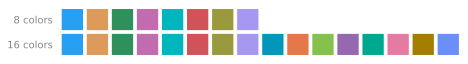

In [6]:
show(c3.palette(8), c3.palette(16), labels=["8 colors", "16 colors"])

### Tones

A tone is the lightness and chroma range the colors come from. The default is `"strong"`.

In [7]:
list(c3.tones)

['vivid', 'bright', 'strong', 'deep', 'dark', 'soft', 'pastel', 'muted']

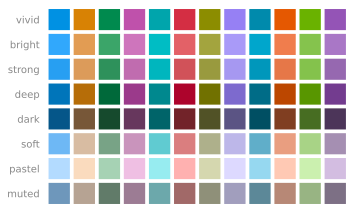

In [8]:
show(*(c3.palette(12, tone=tone) for tone in c3.tones), labels=list(c3.tones))

You can also pass your own ranges, which replace those fields of the default tone, or colors to match: `c3.infer_tone` finds the tone they span.

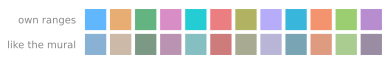

In [9]:
show(
    c3.palette(12, tone={"lightness": (0.7, 0.8), "chroma": (0.1, 0.14)}),
    c3.palette(12, tone=c3.swatches["mural"]),
    labels=["own ranges", "like the mural"],
)

### Offset and direction

`offset` sets the hue of the first color, in degrees on the OKLCH hue circle. Later colors go toward lower hues, or higher ones with `reverse=True`.

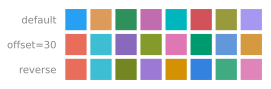

In [10]:
show(
    c3.palette(8),
    c3.palette(8, offset=30),
    c3.palette(8, offset=30, reverse=True),
    labels=["default", "offset=30", "reverse"],
)

### Hue sources

Hues come from the OKLCH hue circle by default. `hue` can also be one of the d3 schemes `"Turbo"`, `"Sinebow"` and `"Rainbow"`, or any function from `t` in [0, 1] to a color, such as a matplotlib colormap. The chroma then follows the scheme's colors.

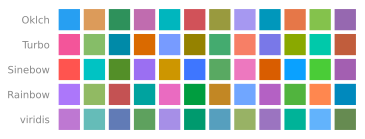

In [11]:
import matplotlib

hues = {
    "Oklch": "Oklch",
    "Turbo": "Turbo",
    "Sinebow": "Sinebow",
    "Rainbow": "Rainbow",
    "viridis": matplotlib.colormaps["viridis"],
}
show(*(c3.palette(12, hue=hue) for hue in hues.values()), labels=list(hues))

### Seeds

`seeds` are colors to start from, such as a few hand-picked ones. They come first and count toward `n`, and the rest are chosen as far from them as possible, in the tone of the seeds.

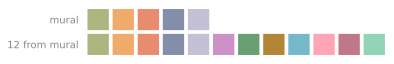

In [12]:
mural = c3.swatches["mural"]
show(mural, c3.palette(12, seeds=mural), labels=["mural", "12 from mural"])

### Weights

Instead of a number, `palette` takes a list of weights, such as category sizes in descending order. Heavy categories keep more free hue on both sides, so they stand out more from the rest.

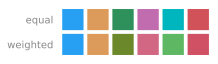

In [13]:
show(c3.palette(6), c3.palette([10, 5, 2, 1, 1, 1]), labels=["equal", "weighted"])

### Many colors

With many colors, later ones get close to earlier ones. With `end="darker"`, the colors after the first ones that fit 0.04 apart, about 30 in the default tone, get their own darker lightness, so they never look like the first ones.

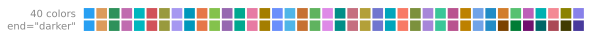

In [14]:
show(c3.palette(40), c3.palette(40, end="darker"), labels=["40 colors", 'end="darker"'])

## Example 1: US states by Census region and division

The US Census Bureau groups the states in four regions and nine divisions. With `c3.hierarchy`, each division gets a color, and its states get shades of it.

We read the state boundaries from the Census cartographic boundary files, at 1:20 million, straight from the URL, and leave out Puerto Rico.

In [15]:
import geopandas as gpd

url = "https://www2.census.gov/geo/tiger/GENZ2025/shp/cb_2025_us_state_20m.zip"
states = gpd.read_file(url).query("STUSPS != 'PR'")
len(states)

51

The regions and divisions, from the Census Bureau:

In [16]:
regions = {
    "Northeast": {
        "New England": ["CT", "ME", "MA", "NH", "RI", "VT"],
        "Middle Atlantic": ["NJ", "NY", "PA"],
    },
    "Midwest": {
        "East North Central": ["IL", "IN", "MI", "OH", "WI"],
        "West North Central": ["IA", "KS", "MN", "MO", "NE", "ND", "SD"],
    },
    "South": {
        "South Atlantic": ["DE", "DC", "FL", "GA", "MD", "NC", "SC", "VA", "WV"],
        "East South Central": ["AL", "KY", "MS", "TN"],
        "West South Central": ["AR", "LA", "OK", "TX"],
    },
    "West": {
        "Mountain": ["AZ", "CO", "ID", "MT", "NV", "NM", "UT", "WY"],
        "Pacific": ["AK", "CA", "HI", "OR", "WA"],
    },
}

`c3.hierarchy` takes modules by path, like `[2, 1, 3]` for the third state of the first division of the second region. It adds the parents itself. Without flows, every state counts the same, so a region with more states gets more room for distinct shades.

In [17]:
paths = {}
for r, divisions in enumerate(regions.values(), 1):
    for d, members in enumerate(divisions.values(), 1):
        for s, state in enumerate(members, 1):
            paths[state] = [r, d, s]

colors = c3.hierarchy([{"path": path} for path in paths.values()])
colors(paths["NY"]), colors(paths["NY"][:2])  # New York, and the Middle Atlantic

('#0ec1e6', '#31b5eb')

To draw the map, we project the lower 48 states to an equal-area projection and put Alaska and Hawaii in insets, not to scale. Simplifying the outlines keeps the figures small.

In [18]:
from matplotlib.patches import Patch

parts = {  # states, projection, and where they go in the figure
    "lower 48": (~states.STUSPS.isin(["AK", "HI"]), "EPSG:5070", [0, 0, 1, 1]),
    "Alaska": (states.STUSPS == "AK", "EPSG:3338", [0, 0, 0.24, 0.3]),
    "Hawaii": (states.STUSPS == "HI", "ESRI:102007", [0.24, 0.02, 0.14, 0.14]),
}
shapes = [
    (states[rows].to_crs(crs).simplify(3000), states.STUSPS[rows], box)
    for rows, crs, box in parts.values()
]


def draw_states(color_of_path, legend=None):
    """Draw the states, each in the color of its path."""
    fig = plt.figure(figsize=(8, 5))
    for geometry, codes, box in shapes:
        ax = fig.add_axes(box)
        fill = [color_of_path(paths[code]) for code in codes]
        geometry.plot(ax=ax, color=fill, edgecolor=gray, linewidth=0.3)
        ax.set_axis_off()
    if legend:
        fig.legend(handles=[Patch(color=c, label=label) for label, c in legend.items()],
                   loc="center left", bbox_to_anchor=(1, 0.5), fontsize=9)
    plt.show()

First the divisions alone: `colors` takes the path of any module, so `path[:2]` gives the color of a state's division.

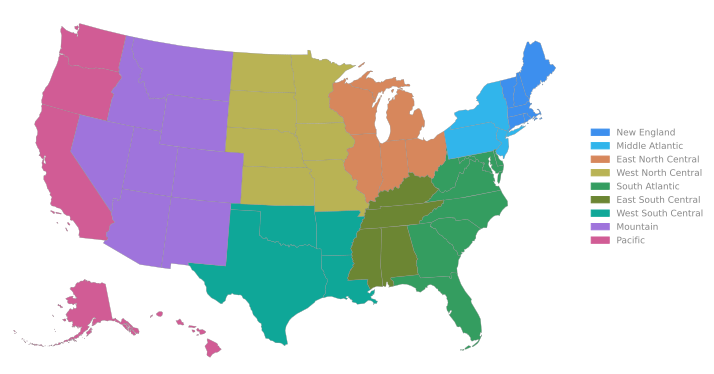

In [19]:
division_colors = {
    division: colors([r, d])
    for r, divisions in enumerate(regions.values(), 1)
    for d, division in enumerate(divisions, 1)
}
draw_states(lambda path: colors(path[:2]), legend=division_colors)

The divisions of a region get nearby hues, like the two blues of the Northeast. And then every state in its own shade of its division's color:

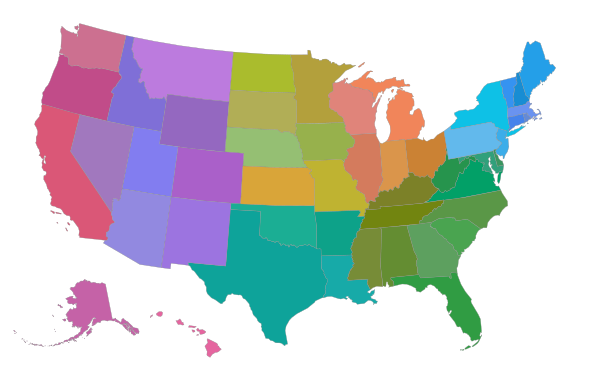

In [20]:
draw_states(colors)

## Example 2: modules in a network

Here is a network with planted nested structure: four groups of two to four subgroups each. Nodes link mostly within their subgroup, sometimes within their group, and rarely between groups.

In [21]:
import networkx as nx

groups = [[12, 10, 9, 8], [11, 9, 7], [10, 8, 8], [9, 7]]  # subgroup sizes per group
sizes = [size for group in groups for size in group]
group_of = [g for g, group in enumerate(groups) for _ in group]
p = [
    [0.6 if a == b else 0.05 if group_of[a] == group_of[b] else 0.003 for b in range(len(sizes))]
    for a in range(len(sizes))
]
G = nx.stochastic_block_model(sizes, p, seed=1)
pos = nx.spring_layout(G, seed=1)
print(G)

Graph named 'stochastic_block_model' with 108 nodes and 321 edges


In [22]:
def draw_network(node_colors, ax=None, title=None):
    """Draw G with the given node colors."""
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 5))
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=gray, alpha=0.5, width=0.5)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors, node_size=40, linewidths=0)
    ax.set_title(title, fontsize=11)
    ax.set_axis_off()

### Flat communities

For flat communities, such as from Louvain, `c3.palette` is all you need. With the community sizes as weights, large communities keep more hue around them.

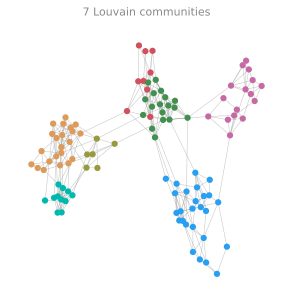

In [23]:
communities = sorted(nx.community.louvain_communities(G, seed=1), key=len, reverse=True)
louvain_colors = c3.palette([len(community) for community in communities])
color_of = {node: color for community, color in zip(communities, louvain_colors) for node in community}

draw_network([color_of[node] for node in G], title=f"{len(communities)} Louvain communities")
plt.show()

### Nested modules

Infomap finds modules within modules. Each node gets a path like `(1, 2, 5)`: the fifth node in submodule 2 of module 1. Modules are numbered by flow, largest first.

In [24]:
from infomap import Infomap

im = Infomap(silent=True, seed=1, num_trials=10)
im.add_networkx_graph(G)
result = im.run()
nodes = list(result.nodes())
print(f"{result.num_top_modules} modules with {result.num_leaf_modules} submodules")

4 modules with 12 submodules


`c3.hierarchy` takes one entry per node, with the node's module path, `path[:-1]`, and its flow. Flows of the same module add up. Large modules get more room, both around their color and for their submodules.

In [25]:
modules = c3.hierarchy([{"path": node.path[:-1], "flow": node.flow} for node in nodes])

for module in modules.modules[:5]:
    print(module["path"], f"flow {module['flow']:.3f}", module["color"])

[1] flow 0.391 #279ff2
[1, 1] flow 0.137 #4684eb
[1, 2] flow 0.111 #2cbad0
[1, 3] flow 0.076 #98a8f8
[1, 4] flow 0.067 #1b8cb7


For a path longer than the known modules, such as a node's full path, `modules` gives the color of the deepest module on it. The top modules on the left, and their submodules, in shades of their module's color, on the right:

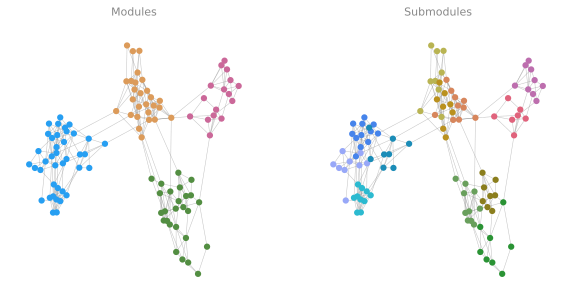

In [26]:
path = {node.node_id: node.path for node in nodes}

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 5))
draw_network([modules(path[node][:1]) for node in G], ax=left, title="Modules")
draw_network([modules(path[node]) for node in G], ax=right, title="Submodules")
plt.show()

## Next steps

The [documentation](https://mapequation.github.io/c3/) explains how the colors are chosen and lists all options, such as `method="farthest"` for the most distinct colors, end zones, and `c3.distance` to measure how far apart two colors are.
C3 is also on npm as [`@mapequation/c3`](https://www.npmjs.com/package/@mapequation/c3), with the same API in JavaScript.